# 04 Validation design (Part B3)

The same two models (logistic regression and LightGBM, `src/models.py`) are scored under three validation schemes. The aim is not to pick a model yet but to find out **which scheme gives an honest estimate of performance on NkwaPay's future applicants**, and how much the others overstate it.

| Scheme | How it splits Train loans | What it simulates |
|---|---|---|
| Stratified 5-fold | Random, class-balanced | Re-scoring a random sample of loans we have already seen |
| Grouped 5-fold | `StratifiedGroupKFold` on `customer_id` | Scoring customers the model has never seen |
| Temporal (expanding window) | Train on loans whose outcome was known before a cut-off, test on the next window | Deploying the model on future loans |

All preprocessing is fitted inside each training fold. Features were built leakage-safe in Section 3, so differences between schemes come from *who* and *when*, not from feature leakage.

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score
from src.config import set_seed, FIGURES, DATA_PROCESSED
from src import models as M, validation as V
set_seed()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
tr = feat[feat.split == "train"].reset_index(drop=True)
tr.shape

(66520, 39)

## 4.1 Temporal folds

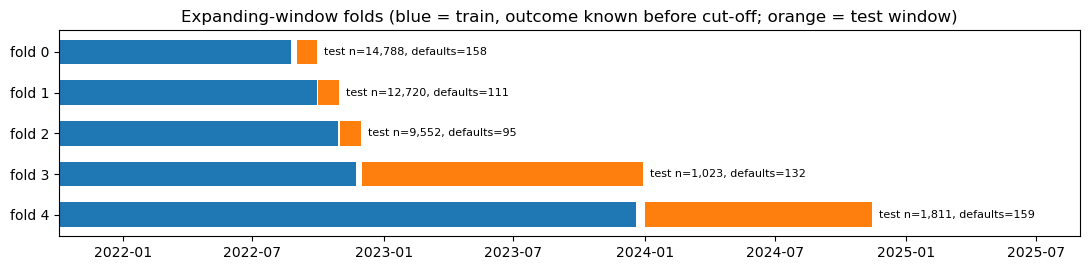

In [2]:
folds_t = list(V.temporal(tr))
fig, ax = plt.subplots(figsize=(11, 2.8))
for i, (a, b) in enumerate(folds_t):
    for idx, c in [(a, "tab:blue"), (b, "tab:orange")]:
        d = tr.disbursement_date.iloc[idx]
        ax.barh(i, (d.max() - d.min()).days, left=d.min(), color=c, height=0.6)
    ax.text(tr.disbursement_date.iloc[b].max(), i, f"  test n={len(b):,}, defaults={int(tr.target.iloc[b].sum())}", va="center", fontsize=8)
ax.set_xlim(right=pd.Timestamp("2025-09-01")); ax.set_yticks(range(len(folds_t)), [f"fold {i}" for i in range(len(folds_t))]); ax.invert_yaxis()
ax.set(title="Expanding-window folds (blue = train, outcome known before cut-off; orange = test window)")
plt.tight_layout(); plt.savefig(FIGURES / "04_temporal_folds.png", dpi=200); plt.show()

Cut-offs are 1 Sep, 1 Oct, 1 Nov and 1 Dec 2022, and 1 Jan 2024. The first three test windows are single high-volume months; the last two pool the thin 2023 and 2024 periods so that each has more than 100 defaults. Training uses only loans whose **due date** is before the cut-off, so no training label comes from the future.

## 4.2 Scores under each scheme

In [3]:
results, oof_store, fold_tables = [], {}, {}
for mname, make in [("logreg", M.logreg), ("lgbm", M.lgbm)]:
    for scheme, split in V.SCHEMES.items():
        oof, fid, folds = V.cross_validate(make(), tr, M.inputs(), split(tr))
        oof_store[(mname, scheme)], fold_tables[(mname, scheme)] = (oof, fid), folds
        results.append({"model": mname, "scheme": scheme, **V.summarise(folds)})
res = pd.DataFrame(results).set_index(["model", "scheme"])
res.round(3)

pr_auc  pr_auc_sd  roc_auc  roc_auc_sd  pr_lift  base_rate
model  scheme                                                                
logreg stratified   0.184      0.026    0.860       0.011   11.314      0.016
       grouped      0.178      0.040    0.856       0.015   10.843      0.016
       temporal     0.129      0.054    0.726       0.084    6.717      0.049
lgbm   stratified   0.233      0.025    0.889       0.016   14.300      0.016
       grouped      0.220      0.044    0.876       0.008   13.500      0.016
       temporal     0.106      0.051    0.726       0.131    5.245      0.049

### Reference: a naive, Zindi-style setup

To show how far a careless pipeline drifts, we also score LightGBM the way the raw competition data invites: **row level** (co-funded loans counted twice), **all raw numeric columns** including the leaky `Total_Amount_to_Repay`, and a random stratified split.

In [4]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src.data import load_rows
raw = load_rows("train")
Xn = pd.get_dummies(raw[["Total_Amount", "Total_Amount_to_Repay", "duration", "Amount_Funded_By_Lender", "Lender_portion_Funded",
                         "Lender_portion_to_be_repaid", "loan_type", "lender_id"]].astype({"lender_id": str}), dtype=float)
p = cross_val_predict(LGBMClassifier(n_estimators=400, learning_rate=0.03, verbose=-1, n_jobs=1, random_state=42), Xn, raw.target,
                      cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
naive = {"pr_auc": average_precision_score(raw.target, p), "roc_auc": roc_auc_score(raw.target, p)}
print(f"Naive row-level, leaky columns, stratified: PR-AUC {naive['pr_auc']:.3f}, ROC-AUC {naive['roc_auc']:.3f}")

Naive row-level, leaky columns, stratified: PR-AUC 0.825, ROC-AUC 0.986


## 4.3 How much does each scheme overstate performance?

In [5]:
infl = []
for m in ["logreg", "lgbm"]:
    r = res.loc[m]
    infl.append({"model": m,
                 "PR-AUC stratified": r.loc["stratified", "pr_auc"], "PR-AUC grouped": r.loc["grouped", "pr_auc"],
                 "PR-AUC temporal": r.loc["temporal", "pr_auc"],
                 "ROC stratified": r.loc["stratified", "roc_auc"], "ROC temporal": r.loc["temporal", "roc_auc"],
                 "lift stratified": r.loc["stratified", "pr_lift"], "lift temporal": r.loc["temporal", "pr_lift"]})
infl = pd.DataFrame(infl).set_index("model")
infl["stratified vs grouped (PR)"] = (infl["PR-AUC stratified"] / infl["PR-AUC grouped"] - 1)
infl["lift: stratified / temporal"] = infl["lift stratified"] / infl["lift temporal"]
infl.to_csv(FIGURES.parent / "04_scheme_comparison.csv")
infl.round(3)

,PR-AUC stratified,PR-AUC grouped,PR-AUC temporal,ROC stratified,ROC temporal,lift stratified,lift temporal,stratified vs grouped (PR),lift: stratified / temporal
model,,,,,,,,,
logreg,0.184,0.178,0.129,0.860,0.726,11.314,6.717,0.036,1.684
lgbm,0.233,0.220,0.106,0.889,0.726,14.300,5.245,0.057,2.726


**Why compare lift as well as PR-AUC.** PR-AUC scales with the share of defaults in the test set, and the temporal folds include the 2023 to 2024 windows where 9 to 13% of loans default, against 1.6% overall. Raw PR-AUC therefore understates how much worse the temporal estimate really is. *Lift* (PR-AUC divided by the fold's default rate) removes that effect: a random ranking scores 1.

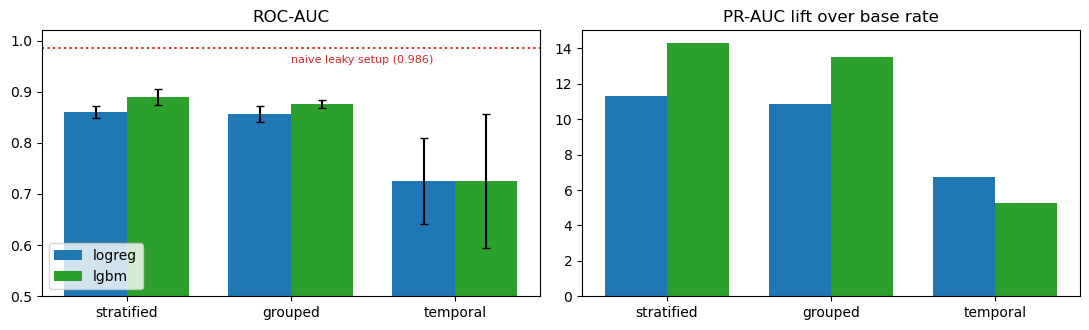

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
order = ["stratified", "grouped", "temporal"]
w = 0.38
for j, (metric, title) in enumerate([("roc_auc", "ROC-AUC"), ("pr_lift", "PR-AUC lift over base rate")]):
    ax = axes[j]
    for k, m in enumerate(["logreg", "lgbm"]):
        vals = res.loc[m].loc[order, metric]
        sd = res.loc[m].loc[order, metric.replace("pr_lift", "pr_auc") + "_sd"] if metric == "roc_auc" else None
        ax.bar(np.arange(3) + (k - .5) * w, vals, w, yerr=sd, capsize=3, label=m, color=["tab:blue", "tab:green"][k])
    ax.set_xticks(range(3), order); ax.set_title(title)
    if metric == "roc_auc": ax.set_ylim(0.5, 1.02); ax.axhline(naive["roc_auc"], ls=":", c="tab:red"); ax.text(1.0, naive["roc_auc"] - .03, f"naive leaky setup ({naive['roc_auc']:.3f})", color="tab:red", fontsize=8)
axes[0].legend(loc="lower left"); plt.tight_layout(); plt.savefig(FIGURES / "04_scheme_comparison.png", dpi=200); plt.show()

## 4.4 Inside the temporal estimate

Fold-level results show that the temporal score hides two very different regimes.

In [7]:
ft = pd.concat({m: fold_tables[(m, "temporal")] for m in ["logreg", "lgbm"]}, names=["model"]).reset_index(level=0)
ft["regime"] = np.where(ft.fold <= 2, "2022 repeat-borrower boom", "Dec 2022 onward")
ft["new_customer_share"] = [(~tr.customer_id.iloc[b].isin(tr.customer_id.iloc[a])).mean() for a, b in folds_t] * 2
display(ft[["model", "fold", "regime", "n_train", "n_test", "defaults", "base_rate", "new_customer_share", "pr_auc", "roc_auc", "pr_lift"]].round(3))
ft.groupby(["regime", "model"])[["roc_auc", "pr_lift"]].mean().round(3)

,model,fold,regime,n_train,n_test,defaults,base_rate,new_customer_share,pr_auc,roc_auc,pr_lift
0,logreg,0,2022 repeat-borrower boom,23191,14788,158,0.011,0.127,0.093,0.783,8.708
1,logreg,1,2022 repeat-borrower boom,37887,12720,111,0.009,0.097,0.097,0.816,11.061
2,logreg,2,2022 repeat-borrower boom,51631,9552,95,0.010,0.019,0.106,0.751,10.618
3,logreg,3,Dec 2022 onward,61783,1023,132,0.129,0.562,0.222,0.664,1.722
4,logreg,4,Dec 2022 onward,64622,1811,159,0.088,0.879,0.130,0.614,1.476
0,lgbm,0,2022 repeat-borrower boom,23191,14788,158,0.011,0.127,0.060,0.815,5.608
1,lgbm,1,2022 repeat-borrower boom,37887,12720,111,0.009,0.097,0.066,0.840,7.590
2,lgbm,2,2022 repeat-borrower boom,51631,9552,95,0.010,0.019,0.102,0.808,10.268
3,lgbm,3,Dec 2022 onward,61783,1023,132,0.129,0.562,0.186,0.597,1.445
4,lgbm,4,Dec 2022 onward,64622,1811,159,0.088,0.879,0.115,0.569,1.315


roc_auc  pr_lift
regime                    model                   
2022 repeat-borrower boom lgbm      0.821    7.822
                          logreg    0.784   10.129
Dec 2022 onward           lgbm      0.583    1.380
                          logreg    0.639    1.599

In [8]:
# Seen versus new customers inside the temporal test windows (pooled out-of-fold scores)
rows = []
for m in ["logreg", "lgbm"]:
    oof, fid = oof_store[(m, "temporal")]
    for i, (a, b) in enumerate(folds_t):
        seen = tr.customer_id.iloc[b].isin(tr.customer_id.iloc[a]).to_numpy()
        for flag, lab in [(True, "seen customer"), (False, "new customer")]:
            idx = b[seen == flag]
            yy = tr.target.iloc[idx]
            if yy.sum() >= 10 and yy.nunique() == 2:
                rows.append({"model": m, "fold": i, "group": lab, "n": len(idx), "defaults": int(yy.sum()),
                             "base_rate": yy.mean(), "roc_auc": roc_auc_score(yy, oof[idx])})
sn = pd.DataFrame(rows)
sn.pivot_table(index=["fold"], columns=["group", "model"], values="roc_auc").round(3)

group new customer        seen customer       
model         lgbm logreg          lgbm logreg
fold                                          
0            0.758  0.672         0.764  0.734
1            0.787  0.770         0.799  0.767
2            0.818  0.796         0.782  0.717
3            0.597  0.651         0.533  0.641
4            0.560  0.605         0.619  0.641

**Reading.** In the 2022 months the models rank borrowers well (ROC about 0.8). From December 2022 default rates jump to 9 to 13%, most borrowers are new to the platform, and both models fall to ROC about 0.6 with lift of only 1.3 to 1.7.

The seen/new split shows that **the drop is a change of regime, not just missing history**. New customers in the 2022 folds were ranked almost as well as repeat ones (ROC 0.67 to 0.82), while in the later folds even *seen* customers are ranked poorly (0.53 to 0.64). Whatever changed in December 2022 (product mix, lenders, the customer base, possibly policy) changed the relationship between features and default, and a model trained on the 2022 boom does not carry over. That is exactly the risk for Ghana: a different market with different products and lenders.

## 4.5 Does the macro block help out of time?

In [9]:
mac = []
for mname, make in [("logreg", M.logreg), ("lgbm", M.lgbm)]:
    for label, cols in [("main (no macro)", M.MAIN_FEATURES), ("with macro", M.WITH_MACRO)]:
        _, _, folds = V.cross_validate(make(numeric=cols), tr, M.inputs(cols), V.temporal(tr))
        mac.append({"model": mname, "features": label, **V.summarise(folds)})
pd.DataFrame(mac).set_index(["model", "features"])[["pr_auc", "roc_auc", "pr_lift"]].round(3)

pr_auc  roc_auc  pr_lift
model  features                                 
logreg main (no macro)   0.129    0.726    6.717
       with macro        0.128    0.726    6.732
lgbm   main (no macro)   0.106    0.726    5.245
       with macro        0.107    0.729    5.258

Adding the macro block changes PR-AUC and ROC by at most 0.003 for either model. It cannot help: within Kenya it only distinguishes years, and the model already sees the date through history features. It stays **out of the main model** (simpler, and it avoids extrapolating to Ghana's 31% inflation).

## 4.6 Decision

**We use the temporal expanding-window scheme (5 folds) for every model comparison, threshold choice and reported number from Section 5 onward**, and report each result both pooled and split into the two regimes.

*Why.*
1. NkwaPay will score **future** applicants. Only the temporal scheme trains on the past and tests on the future, and only it exposes the regime change from December 2022.
2. The random schemes do not just inflate the score, they **change which model looks best**: LightGBM beats logistic regression by 0.05 PR-AUC under stratified CV, but out of time it is worse on PR-AUC (0.106 against 0.129), equal on pooled ROC, and worse on both in the post-2022 regime. Choosing a model with stratified CV would pick the wrong one.
3. The naive setup (row level, leaky columns, random split) reports PR-AUC 0.825 and ROC 0.986, **six to eight times the honest temporal PR-AUC**. Almost all of that comes from the leaky repay column (Section 1).
4. Stratified versus grouped differs only modestly (about 3 to 6% in PR-AUC) because our history features are leakage-safe; the much larger gap is **time**, not customer memorisation. GroupKFold remains a useful secondary check for "new customer" performance.
5. The temporal training sets respect label timing: a loan enters training only once its outcome was observable.

*Costs we accept.* Temporal folds have fewer test defaults and more variance (PR-AUC sd about 0.05), and the late folds are small (1,023 and 1,811 loans). Section 7 adds bootstrap intervals so that differences between models are not over-read.

*For Part C.* The post-2022, mostly-new-customer folds are our best Kenyan proxy for Ghana, and on them the models are only slightly better than chance. Any claim about Ghana performance has to start from these numbers, not from the 0.86 to 0.89 ROC of random CV.